# 12: Waste-burning budget — how fast can the actinide inventory be cleared, and what does the neutron driver cost?

Notebook 11 identified partitioning and transmutation (P&T) as the nearest-term way to cut the spent-fuel hazard from ~300,000 to ~300 years. This notebook puts numbers on it:

1. **Burn rate:** tonnes of transuranics (TRU) fissioned per GWth-year (energy bookkeeping only).
2. **Inventory and time to clear** for a given fleet of burners.
3. **Driver cost** for a subcritical (ADS) burner: the fraction of electrical output spent on the neutron source, for spallation and for the muon-catalysed (μCF) sources of notebook 10.
4. **Long-lived fission products** (⁹⁹Tc, ¹²⁹I): they absorb neutrons without producing energy. Can the subcritical source margin pay for them?

**Input status.** Physics inputs are standard (200 MeV per fission, ν ≈ 2.9 for TRU in a fast spectrum, cumulative fission yields of ⁹⁹Tc ≈ 6.1% and ¹²⁹I ≈ 0.7% for ²³⁵U, similar for ²³⁹Pu). Inventory figures are **secondary and unverified** (IAEA/NEA summaries as recalled: ~4×10⁵ t heavy metal of spent fuel worldwide, ~1.2% of it TRU). Treat the clearance times as order-of-magnitude.

In [1]:
import numpy as np, matplotlib.pyplot as plt
plt.rcParams.update({"axes.spines.top":False,"axes.spines.right":False,"axes.grid":True,"grid.alpha":.25,"font.size":10})
BLUE, ORANGE, AQUA, MAGENTA = "#2a78d6","#eb6834","#1baf7a","#e87ba4"
MEV = 1.602176634e-13; YEAR = 3.15576e7; NA = 6.02214076e23
E_FIS = 200.0                 # MeV recoverable per fission
A_TRU = 241.0                 # g/mol, typical TRU mix
NU_TRU = 2.9                  # neutrons per TRU fission, fast spectrum
fis_per_GWthyr = 1e9*YEAR/(E_FIS*MEV)
t_per_GWthyr = fis_per_GWthyr*A_TRU/NA/1e6
print(f"fissions per GWth-year: {fis_per_GWthyr:.3e}")
print(f"TRU fissioned per GWth-year: {t_per_GWthyr:.3f} t  (same mass of fission products produced)")

fissions per GWth-year: 9.848e+26
TRU fissioned per GWth-year: 0.394 t  (same mass of fission products produced)


In [2]:
# Inventory (SECONDARY, unverified) and time to clear
SF_WORLD = 4.0e5; TRU_FRAC = 0.012
TRU_world = SF_WORLD*TRU_FRAC
print(f"world TRU inventory (assumed): {TRU_world:,.0f} t  -> {TRU_world/t_per_GWthyr:,.0f} GWth-years to fission it all")
# A burner only fissions the TRU it is fed; the LWR fleet keeps adding ~ 0.25 t TRU per GWe-year (secondary, recalled)
ADD_PER_GWe_yr = 0.25; LWR_GWe = 370
add_rate = ADD_PER_GWe_yr*LWR_GWe
print(f"ongoing TRU production by ~{LWR_GWe} GWe of LWRs: ~{add_rate:.0f} t/yr -> {add_rate/t_per_GWthyr:.0f} GWth of burners just to keep level")
for P in [100, 300, 1000]:
    net = P*t_per_GWthyr - add_rate
    T = TRU_world/net if net > 0 else np.inf
    print(f"  {P:5d} GWth of TRU burners: net burn {net:6.0f} t/yr, clear the stock in {T:6.0f} years")

world TRU inventory (assumed): 4,800 t  -> 12,179 GWth-years to fission it all
ongoing TRU production by ~370 GWe of LWRs: ~92 t/yr -> 235 GWth of burners just to keep level
    100 GWth of TRU burners: net burn    -53 t/yr, clear the stock in    inf years
    300 GWth of TRU burners: net burn     26 t/yr, clear the stock in    187 years
   1000 GWth of TRU burners: net burn    302 t/yr, clear the stock in     16 years


In [3]:
# Driver cost in an ADS burner: source neutrons needed per fission = (1-k) nu / k
ETA_TH, ETA_ACC = 0.40, 0.40
SOURCES = {"spallation (27.5 n/GeV)": 27.5, "μCF today (30 n/GeV)": 30.0,
           "μCF, muon cost /2.5 (75 n/GeV)": 75.0, "μCF, all levers (168 n/GeV)": 168.0}
ks = np.array([0.90, 0.95, 0.97, 0.98])
print("fraction of the plant's electrical output spent on the driver")
print(f"{'source':34s}" + "".join(f"  k={k:.2f}" for k in ks))
frac = {}
for name, n in SOURCES.items():
    src_per_fis = (1 - ks)*NU_TRU/ks
    beam_GeV_per_fis = src_per_fis/n
    f = (beam_GeV_per_fis*1e3/ETA_ACC)/(E_FIS*ETA_TH)     # driver electricity / gross electricity
    frac[name] = f
    print(f"{name:34s}" + "".join(f"  {x:6.3f}" for x in f))

fraction of the plant's electrical output spent on the driver
source                              k=0.90  k=0.95  k=0.97  k=0.98
spallation (27.5 n/GeV)              0.366   0.173   0.102   0.067
μCF today (30 n/GeV)                 0.336   0.159   0.093   0.062
μCF, muon cost /2.5 (75 n/GeV)       0.134   0.064   0.037   0.025
μCF, all levers (168 n/GeV)          0.060   0.028   0.017   0.011


In [4]:
# Long-lived fission products: neutrons needed per fission vs neutrons the source supplies
Y_TC, Y_I = 0.061, 0.007
need_llfp = Y_TC + Y_I
print(f"neutrons to transmute 99Tc + 129I made per fission: {need_llfp:.3f}")
for k in ks:
    s = (1 - k)*NU_TRU/k
    print(f"  k = {k:.2f}: source neutrons per fission {s:.3f}  -> covers LLFP {'yes' if s >= need_llfp else 'no'} (ratio {s/need_llfp:.2f})")

neutrons to transmute 99Tc + 129I made per fission: 0.068
  k = 0.90: source neutrons per fission 0.322  -> covers LLFP yes (ratio 4.74)
  k = 0.95: source neutrons per fission 0.153  -> covers LLFP yes (ratio 2.24)
  k = 0.97: source neutrons per fission 0.090  -> covers LLFP yes (ratio 1.32)
  k = 0.98: source neutrons per fission 0.059  -> covers LLFP no (ratio 0.87)


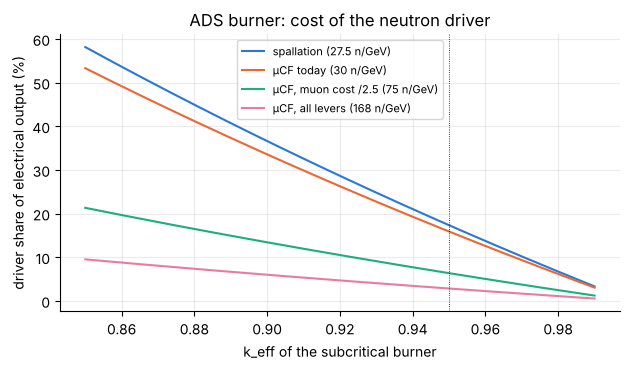

In [5]:
fig, ax = plt.subplots(figsize=(6.4, 3.8))
kk = np.linspace(0.85, 0.99, 200)
for (name, n), c in zip(SOURCES.items(), [BLUE, ORANGE, AQUA, MAGENTA]):
    f = ((1 - kk)*NU_TRU/kk/n*1e3/ETA_ACC)/(E_FIS*ETA_TH)
    ax.plot(kk, 100*f, color=c, label=name)
ax.axvline(0.95, color="k", lw=.6, ls=":")
ax.set_xlabel("k_eff of the subcritical burner"); ax.set_ylabel("driver share of electrical output (%)")
ax.set_title("ADS burner: cost of the neutron driver"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("../figures/12_driver_share.png", dpi=160); plt.show()

## Interpretation

Numbers from the printed results above. Inventories are secondary and unverified.

* **Burn rate is fixed by energy:** fissioning 0.394 t of TRU releases 1 GWth-year. The assumed world stock (~4,800 t TRU) is ~12,200 GWth-years of heat, a valuable fuel rather than just a liability.
* **The fleet has to outrun production.** ~370 GWe of light-water reactors add ~92 t TRU per year, which takes ~235 GWth of burners just to hold the stock level. 300 GWth of burners clears the stock in ~190 years; 1,000 GWth clears it in ~16 years. Clearing is a fleet-scale commitment, not a demonstration-scale one.
* **The driver costs 17% of output at k = 0.95 with spallation**, falling to 7–10% at k = 0.97–0.98. μCF *today* (30 n/GeV) is no better than spallation (16% vs 17%). Only with the notebook 09 levers does μCF cut the driver share to 3–6% at k = 0.95. Fusion energy and the 14 MeV source spectrum are ignored, which slightly favours spallation.
* **Long-lived fission products:** transmuting the ⁹⁹Tc and ¹²⁹I made per fission takes ~0.07 neutrons. A subcritical burner at k ≤ 0.97 supplies more source neutrons than that (ratio 1.3–4.7); at k = 0.98 it does not (0.87). This is an upper bound on what is available, since not every source neutron reaches a target. It is the one concrete advantage of a strong external source over a critical fast reactor: the spare neutrons can clean up fission products as well as actinides.

**Bottom line:** the waste problem is neutron- and fleet-limited, not physics-limited. A better neutron source (μCF with the notebook 09 levers) would cut the driver penalty roughly six-fold, but it would not change the fleet size needed to clear the stock, which energy bookkeeping sets.